In [1]:
!git clone https://github.com/nicknochnack/ANPRwithPython.git
%cd ANPRwithPython

Cloning into 'ANPRwithPython'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 7 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 596.17 KiB | 2.85 MiB/s, done.
/content/ANPRwithPython


In [2]:
!pip install easyocr
!pip install imutils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 422.8/422.8 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9

In [34]:
from google.colab import files
uploaded = files.upload()

Saving img2.jpeg to img2.jpeg


In [3]:
import cv2
from matplotlib import pyplot as plt
import numpy as np
import imutils
import easyocr

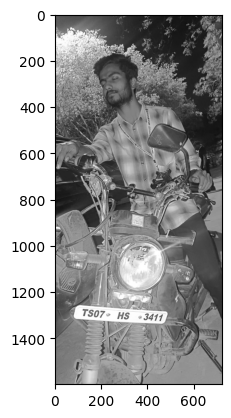

In [35]:
img = cv2.imread('/content/ANPRwithPython/img2.jpeg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(cv2.cvtColor(gray, cv2.COLOR_BGR2RGB))

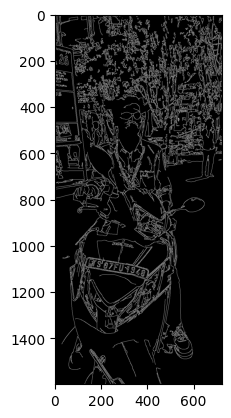

In [27]:
bfilter = cv2.bilateralFilter(gray, 11, 17, 17) #Noise reduction
edged = cv2.Canny(bfilter, 30, 200) #Edge detection
plt.imshow(cv2.cvtColor(edged, cv2.COLOR_BGR2RGB))

In [38]:
keypoints = cv2.findContours(edged.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
contours = imutils.grab_contours(keypoints)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

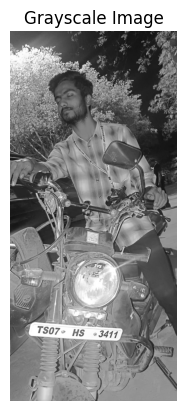

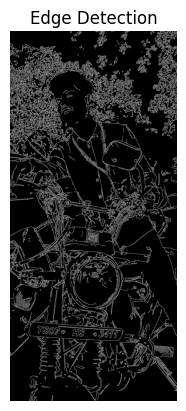

No suitable contour found!


In [46]:
import cv2
from matplotlib import pyplot as plt
import numpy as np
import imutils
import easyocr

# Load image
img = cv2.imread('/content/ANPRwithPython/img2.jpeg')

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display grayscale image
plt.imshow(cv2.cvtColor(gray, cv2.COLOR_BGR2RGB))
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

# Apply bilateral filter (Noise Reduction)
bfilter = cv2.bilateralFilter(gray, 11, 17, 17)

# Apply Canny Edge Detection
edged = cv2.Canny(bfilter, 50, 150)  # Adjust the thresholds


# Display edge-detected image
plt.imshow(cv2.cvtColor(edged, cv2.COLOR_BGR2RGB))
plt.title("Edge Detection")
plt.axis("off")
plt.show()

# Find contours
keypoints = cv2.findContours(edged.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
contours = imutils.grab_contours(keypoints)

# Sort contours by area (keep the 10 largest)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

# Select the contour that likely represents a license plate
location = None
for contour in contours:
    approx = cv2.approxPolyDP(contour, 10, True)  # Approximate the contour
    if len(approx) == 4:  # If it has 4 points, it might be a license plate
        location = approx
        break

# Check if a valid contour was found
if location is None:
    print("No suitable contour found!")
else:
    print("License plate detected!")

# Create a mask and extract the license plate area
mask = np.zeros(gray.shape, np.uint8)

if location is not None:
    cv2.drawContours(mask, [location], 0, 255, -1)  # Draw the contour
    new_image = cv2.bitwise_and(img, img, mask=mask)  # Apply the mask

    # Show the extracted license plate
    plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))
    plt.title("Extracted License Plate")
    plt.axis("off")
    plt.show()


In [47]:
location = np.array(location, dtype=np.int32)
for contour in contours:
    approx = cv2.approxPolyDP(contour, 10, True)
    if len(approx) == 4:
        location = approx
        break

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

In [43]:
import numpy as np
import cv2

# Ensure 'location' is a NumPy array with shape (N, 1, 2) and int32 type
location = np.array(location, dtype=np.int32)  # Convert to NumPy array

if location.ndim == 2:  # If it's (N, 2), reshape it to (N, 1, 2)
    location = location.reshape(-1, 1, 2)

# Create a blank mask
mask = np.zeros(gray.shape, np.uint8)

# Draw contour on the mask
cv2.drawContours(mask, [location], 0, 255, -1)  # Ensure correct format

# Apply mask to the image
new_image = cv2.bitwise_and(img, img, mask=mask)


TypeError: int() argument must be a string, a bytes-like object or a real number, not 'NoneType'

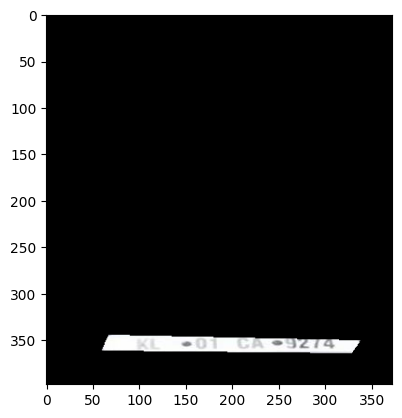

In [ ]:
plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))

In [48]:
(x,y) = np.where(mask==255)
(x1, y1) = (np.min(x), np.min(y))
(x2, y2) = (np.max(x), np.max(y))
cropped_image = gray[x1:x2+1, y1:y2+1]

ValueError: zero-size array to reduction operation minimum which has no identity

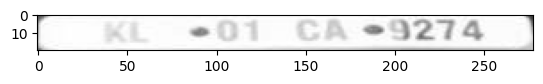

In [ ]:
plt.imshow(cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB))

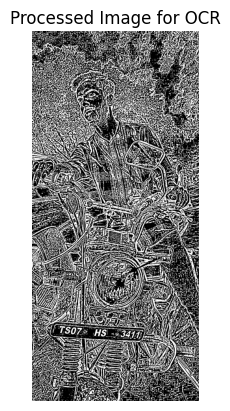

[([[np.int32(265), np.int32(1283)], [np.int32(329), np.int32(1283)], [np.int32(329), np.int32(1325)], [np.int32(265), np.int32(1325)]], 'HS}', np.float64(0.39167327735143503)), ([[np.int32(355), np.int32(1291)], [np.int32(451), np.int32(1291)], [np.int32(451), np.int32(1331)], [np.int32(355), np.int32(1331)]], '2 341', np.float64(0.5450497466232856)), ([[np.float64(115.00019994002), np.float64(1264.1009797060979)], [np.float64(222.85605422049053), np.float64(1279.8088923610117)], [np.float64(214.99980005998), np.float64(1322.8990202939021)], [np.float64(107.14394577950948), np.float64(1308.1911076389883)]], 'T507', np.float64(0.44122663140296936))]


In [49]:
# Convert to grayscale

import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt


# Increase contrast using CLAHE (better than Histogram Equalization)
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
enhanced = clahe.apply(gray)

# Apply adaptive thresholding
thresh = cv2.adaptiveThreshold(
    enhanced, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)

# Optional: Invert colors if text is dark on a light background
thresh = cv2.bitwise_not(thresh)

# Show processed image
plt.imshow(thresh, cmap="gray")
plt.title("Processed Image for OCR")
plt.axis("off")
plt.show()

# Perform OCR with EasyOCR
reader = easyocr.Reader(['en'])
result = reader.readtext(thresh)

# Print detected text
print(result)


In [37]:
# Convert processed grayscale image to RGB
rgb_image = cv2.cvtColor(thresh, cv2.COLOR_GRAY2RGB)

# Perform OCR using EasyOCR
reader = easyocr.Reader(['en'])
result = reader.readtext(rgb_image)  # Pass the RGB-converted image

# Print detected text
for (bbox, text, prob) in result:
    print(f"Detected: {text} (Confidence: {prob:.2f})")


Detected: HS} (Confidence: 0.39)
Detected: 2 341 (Confidence: 0.55)
Detected: T507 (Confidence: 0.44)
